# Representaciones 3D en Python — Tutorial práctico

**Curso:** Procesamiento Geométrico &nbsp;·&nbsp; **Duración:** ~60 minutos &nbsp;·&nbsp; **Entorno:** Google Colab

En procesamiento geométrico un mismo objeto puede describirse de varias maneras, y cada una
hace fácil una cosa y difícil otra. En este tutorial vas a manipular las cuatro
representaciones más usadas y, sobre todo, vas a ver **cómo se pasa de una a otra**.

| Representación | Estructura de datos | Buena para | Mala para |
|---|---|---|---|
| Nube de puntos | `(N, 3)` de coordenadas | datos de sensores, registro, vecindarios | topología, superficies cerradas |
| Malla poligonal | vértices `(V, 3)` + caras `(F, 3)` | render, geodésicas, simulación | booleanas, garantizar validez |
| Voxels / grilla | ocupancia `(n, n, n)` | booleanas, convoluciones/redes 3D | memoria O(n³), detalle fino |
| Implícita (SDF) | función `f(x,y,z) → ℝ` | booleanas, offsets, blending | render directo, detalle no uniforme |

### Agenda

| | Sección | Tiempo |
|---|---|---|
| 0 | Preparación del entorno | 5 min |
| 1 | Nubes de puntos | 12 min |
| 2 | Mallas poligonales | 15 min |
| 3 | Voxels y grillas de ocupancia | 10 min |
| 4 | Superficies implícitas (SDF) y *marching cubes* | 12 min |
| 5 | Superficies paramétricas | 6 min |
| 6 | Cierre: el mapa de conversiones | — |

### Cómo usar este notebook

* Las celdas marcadas **🔧** son demostraciones: **ejecútalas y lee el código**, no hay que escribir nada.
* Las celdas marcadas **✏️ EJERCICIO** tienen `TODO` que debes completar. Cada una trae una celda de
  verificación con `assert`: si pasa sin quejarse, tu solución está bien.
* Los ejercicios marcados **★** son opcionales (para después de la clase si no alcanza el tiempo).
* Todas las visualizaciones son con Plotly y se ven **dentro** del notebook: puedes rotar con el mouse,
  hacer zoom con la rueda y ocultar trazas haciendo clic en la leyenda.

---
## 0. Preparación del entorno &nbsp; ⏱ ~5 min

La primera celda instala las dependencias (en Colab demora ~1 minuto). La segunda define las
funciones de visualización que usaremos todo el tutorial: **no necesitas entenderlas en detalle**,
pero échales un vistazo porque muestran cómo se convierte cada representación en algo dibujable.

In [1]:
# 🔧 Instalación (ejecutar una sola vez)
try:
    import open3d
except ImportError:
    !pip install -q open3d
try:
    import skimage
except ImportError:
    !pip install -q scikit-image
try:
    import plotly
except ImportError:
    !pip install -q plotly

import open3d as o3d, numpy as np, plotly, skimage
print("open3d:", o3d.__version__, "| numpy:", np.__version__, "| plotly:", plotly.__version__)

open3d: 0.19.0+4356c1727 | numpy: 2.5.2 | plotly: 6.9.0


In [2]:
# 🔧 Utilidades de visualización (Plotly) — ejecutar y seguir
import copy
import numpy as np
import open3d as o3d
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

try:                      # renderer correcto dentro de Colab
    import google.colab   # noqa: F401
    pio.renderers.default = "colab"
except ImportError:
    pass

rng = np.random.default_rng(42)      # aleatoriedad de numpy
o3d.utility.random.seed(42)          # aleatoriedad interna de Open3D (muestreos reproducibles)


def _fig(title="", data=(), size=560):
    fig = go.Figure(data=list(data))
    fig.update_layout(title=title, width=size, height=size,
                      margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(aspectmode="data"))   # aspectmode='data' = sin distorsión
    return fig


def _rgb(c):
    c = np.clip(np.atleast_2d(np.asarray(c, float)), 0, 1)
    return ["rgb(%d,%d,%d)" % tuple(v) for v in (c * 255).astype(int)]


def show_points(pcd, color=None, size=2.0, title="", normals=False,
                n_normals=150, max_points=60000):
    # pcd: o3d.geometry.PointCloud o array (N,3). color: str | array (N,) | array (N,3)
    P = np.asarray(pcd.points) if isinstance(pcd, o3d.geometry.PointCloud) else np.asarray(pcd)
    N = np.asarray(pcd.normals) if isinstance(pcd, o3d.geometry.PointCloud) and pcd.has_normals() else None
    if color is None and isinstance(pcd, o3d.geometry.PointCloud) and pcd.has_colors():
        color = np.asarray(pcd.colors)
    if len(P) > max_points:                      # submuestreo solo para dibujar
        sel = rng.choice(len(P), max_points, replace=False)
        P = P[sel]
        N = None if N is None else N[sel]
        if color is not None and not isinstance(color, str):
            color = np.asarray(color)[sel]

    marker = dict(size=size)
    if color is None:
        marker.update(color=P[:, 1], colorscale="Viridis")
    elif isinstance(color, str):
        marker.update(color=color)
    else:
        c = np.asarray(color, float)
        marker.update(color=_rgb(c) if c.ndim == 2 else c)
        if c.ndim == 1:
            marker.update(colorscale="Viridis", showscale=True,
                          colorbar=dict(thickness=12, len=0.6))
    data = [go.Scatter3d(x=P[:, 0], y=P[:, 1], z=P[:, 2], mode="markers",
                         marker=marker, name="puntos")]

    if normals and N is not None:
        sel = rng.choice(len(P), min(n_normals, len(P)), replace=False)
        s = 0.05 * np.linalg.norm(P.max(0) - P.min(0))
        seg = np.full((len(sel) * 3, 3), np.nan)
        seg[0::3], seg[1::3] = P[sel], P[sel] + s * N[sel]
        data.append(go.Scatter3d(x=seg[:, 0], y=seg[:, 1], z=seg[:, 2], mode="lines",
                                 line=dict(color="crimson", width=3), name="normales"))
    return _fig(title, data)


def show_mesh(mesh, color="lightsteelblue", opacity=1.0, title="",
              wireframe=False, flat=False):
    V, F = np.asarray(mesh.vertices), np.asarray(mesh.triangles)
    kw = {}
    if mesh.has_vertex_colors():
        kw["vertexcolor"] = (np.asarray(mesh.vertex_colors) * 255).astype(np.uint8)
    else:
        kw["color"] = color
    data = [go.Mesh3d(x=V[:, 0], y=V[:, 1], z=V[:, 2],
                      i=F[:, 0], j=F[:, 1], k=F[:, 2],
                      opacity=opacity, flatshading=flat, name="malla",
                      lighting=dict(ambient=0.45, diffuse=0.85, specular=0.15), **kw)]
    if wireframe and len(F) <= 25000:
        E = np.concatenate([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]])
        seg = np.full((len(E) * 3, 3), np.nan)
        seg[0::3], seg[1::3] = V[E[:, 0]], V[E[:, 1]]
        data.append(go.Scatter3d(x=seg[:, 0], y=seg[:, 1], z=seg[:, 2], mode="lines",
                                 line=dict(color="black", width=1), name="aristas"))
    return _fig(title, data)


_CUBE_V = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0],
                    [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]], float)
_CUBE_F = np.array([[0, 2, 1], [0, 3, 2], [4, 5, 6], [4, 6, 7], [0, 1, 5], [0, 5, 4],
                    [1, 2, 6], [1, 6, 5], [2, 3, 7], [2, 7, 6], [3, 0, 4], [3, 4, 7]])


def voxels_to_mesh(centers, size):
    # convierte centros de voxel (M,3) en una malla de cubos, para poder dibujarlos
    centers = np.asarray(centers, float)
    V = (centers[:, None, :] + size * (_CUBE_V - 0.5)[None]).reshape(-1, 3)
    F = (_CUBE_F[None] + 8 * np.arange(len(centers))[:, None, None]).reshape(-1, 3)
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(V),
                                  o3d.utility.Vector3iVector(F))
    m.compute_vertex_normals()
    return m


def show_voxelgrid(vg, title="", color="sandybrown", max_voxels=12000):
    vx = vg.get_voxels()
    idx = np.array([v.grid_index for v in vx])
    if len(idx) > max_voxels:
        idx = idx[rng.choice(len(idx), max_voxels, replace=False)]
        title += "  (submuestreado para dibujar)"
    centers = np.asarray(vg.origin) + (idx + 0.5) * vg.voxel_size
    return show_mesh(voxels_to_mesh(centers, vg.voxel_size * 0.95),
                     color=color, title=title, flat=True)


def side_by_side(figs, titles, size=(980, 480)):
    fig = make_subplots(rows=1, cols=len(figs), subplot_titles=titles,
                        specs=[[{"type": "scene"}] * len(figs)])
    for c, f in enumerate(figs, 1):
        for tr in f.data:
            fig.add_trace(tr, row=1, col=c)
        fig.update_layout(**{("scene" if c == 1 else f"scene{c}"): dict(aspectmode="data")})
    fig.update_layout(width=size[0], height=size[1], showlegend=False,
                      margin=dict(l=0, r=0, t=40, b=0))
    return fig


def es_cerrada(m):
    # "cerrada" = sin aristas de borde: cada arista pertenece exactamente a 2 triángulos.
    # (is_watertight() además testea auto-intersecciones y es poco confiable en mallas de
    #  marching cubes, que traen triángulos casi degenerados)
    return m.is_edge_manifold(allow_boundary_edges=False)


def normalize(mesh):
    # centra la malla en el origen y la escala para que quepa en [-1,1]^3
    m = copy.deepcopy(mesh)
    V = np.asarray(m.vertices)
    V = (V - V.mean(0)) / np.abs(V - V.mean(0)).max()
    m.vertices = o3d.utility.Vector3dVector(V)
    m.compute_vertex_normals()
    return m


def load_bunny():
    # descarga el conejo de Stanford; si no hay red, cae en una malla sintética
    try:
        mesh = o3d.io.read_triangle_mesh(o3d.data.BunnyMesh().path)
        mesh.remove_duplicated_vertices()
        mesh.remove_degenerate_triangles()
    except Exception as e:
        print("No se pudo descargar el modelo (", e, ") -> uso un toro sintético.")
        mesh = o3d.geometry.TriangleMesh.create_torus(radial_resolution=60, tubular_resolution=30)
    return normalize(mesh)


print("Utilidades cargadas ✔")

Utilidades cargadas ✔


---
## 1. Nubes de puntos &nbsp; ⏱ ~12 min

Una nube de puntos es, literalmente, **una matriz `(N, 3)`**: no hay conectividad, no hay superficie,
solo muestras del objeto. Es lo que entrega un escáner láser o una cámara de profundidad.

Todo lo que "sabe" una nube sobre su vecindad hay que **calcularlo**: normales, densidad,
curvatura... y para eso siempre aparece la misma herramienta, una estructura de búsqueda espacial
(**KD-tree**).

### 1.1 Una nube es un array de numpy

PointCloud with 3000 points.
de vuelta a numpy: (3000, 3)


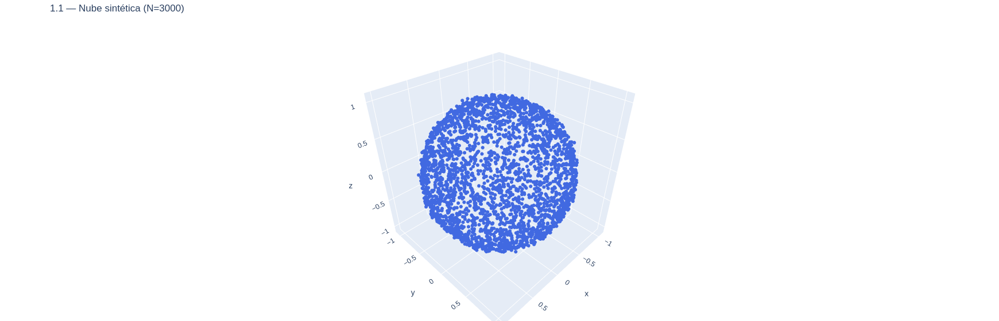

In [3]:
# 🔧 Creamos una nube "a mano": puntos sobre una esfera + ruido radial
n = 3000
d = rng.normal(size=(n, 3))
d /= np.linalg.norm(d, axis=1, keepdims=True)          # direcciones uniformes en la esfera
P = d * (1.0 + 0.02 * rng.normal(size=(n, 1)))         # radio 1 con ruido

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(P)             # numpy -> open3d
print(pcd)
print("de vuelta a numpy:", np.asarray(pcd.points).shape)

show_points(pcd, color="royalblue", title="1.1 — Nube sintética (N=3000)")

`Vector3dVector` es solo un envoltorio: `np.asarray(pcd.points)` te devuelve el array sin copiar datos
pesados. **Regla práctica: haz los cálculos en numpy y usa Open3D para estructuras y algoritmos.**

### 1.2 De malla a nube: muestreo de superficie

malla: TriangleMesh with 35947 points and 69451 triangles.


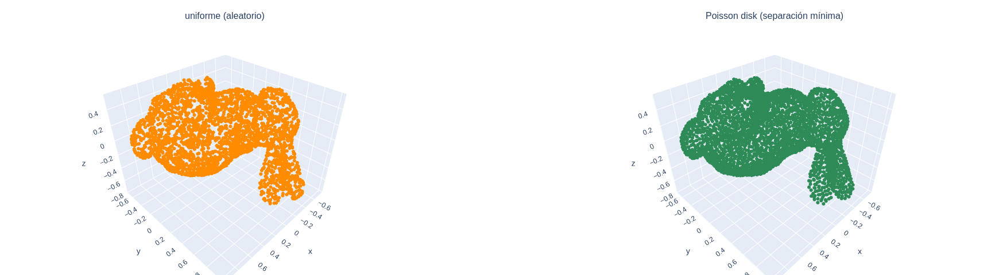

In [4]:
# 🔧 Cargamos el conejo de Stanford y lo muestreamos de dos formas distintas
bunny = load_bunny()
print("malla:", bunny)

pcd_unif = bunny.sample_points_uniformly(number_of_points=3000)
pcd_pois = bunny.sample_points_poisson_disk(number_of_points=3000)

side_by_side(
    [show_points(pcd_unif, color="darkorange", size=2),
     show_points(pcd_pois, color="seagreen", size=2)],
    ["uniforme (aleatorio)", "Poisson disk (separación mínima)"])

Ambas nubes tienen 3000 puntos, pero el muestreo uniforme deja grumos y huecos, mientras que
*Poisson disk* garantiza una distancia mínima entre puntos. Cuando el muestreo alimenta un algoritmo
posterior (estimar normales, reconstruir superficie) esa regularidad **importa mucho**; el costo es
que es bastante más lento.

### 1.3 Reducir la nube: submuestreo por voxel

voxel_size=0.02 ->  20272 puntos
voxel_size=0.05 ->   3656 puntos
voxel_size=0.10 ->    957 puntos


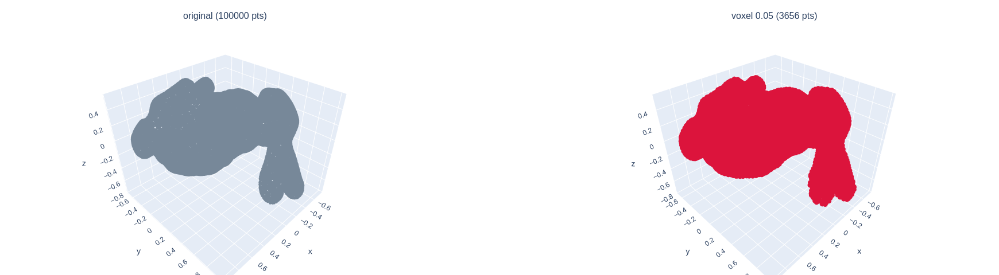

In [5]:
# 🔧 voxel_down_sample: una grilla imaginaria y un punto (el promedio) por celda ocupada
pcd_full = bunny.sample_points_uniformly(number_of_points=100000)

for s in [0.02, 0.05, 0.10]:
    print(f"voxel_size={s:.2f} -> {len(pcd_full.voxel_down_sample(s).points):6d} puntos")

down = pcd_full.voxel_down_sample(0.05)
side_by_side([show_points(pcd_full, color="lightslategray", size=1),
              show_points(down, color="crimson", size=3)],
             [f"original ({len(pcd_full.points)} pts)", f"voxel 0.05 ({len(down.points)} pts)"])

Fíjate en la diferencia con `random_down_sample`: el submuestreo por voxel **uniformiza la densidad**
(una celda muy poblada aporta un solo punto), mientras que el aleatorio conserva las zonas densas
densas. Casi todo pipeline de nubes empieza con un `voxel_down_sample`.

### 1.4 Normales: la geometría local que la nube no trae

normales: (6000, 3) | norma media: 1.0


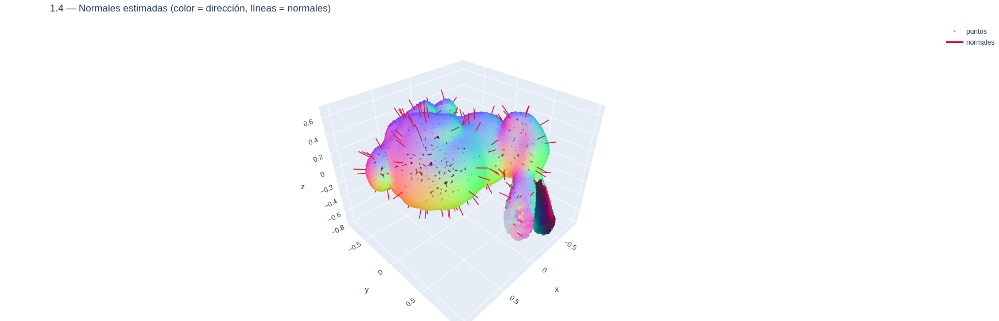

In [6]:
# 🔧 Cada normal se estima con PCA sobre los k vecinos más cercanos:
#    la normal es el autovector de menor varianza del vecindario.
pcd = bunny.sample_points_poisson_disk(number_of_points=6000)
pcd.estimate_normals(o3d.geometry.KDTreeSearchParamKNN(knn=30))
pcd.orient_normals_consistent_tangent_plane(k=15)   # PCA no define el signo: hay que orientarlas

Nrm = np.asarray(pcd.normals)
print("normales:", Nrm.shape, "| norma media:", np.linalg.norm(Nrm, axis=1).mean())

show_points(pcd, color=(0.5 * Nrm + 0.5), size=2.5, normals=True,
            title="1.4 — Normales estimadas (color = dirección, líneas = normales)")

### 1.5 Vecindarios con KD-tree

knn -> 50 vecinos | radio 0.15 -> 93 vecinos


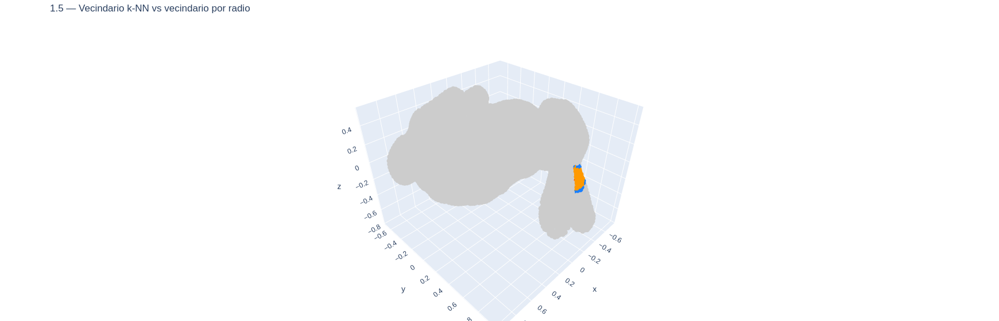

In [7]:
# 🔧 El KD-tree responde dos preguntas: "los k más cercanos" y "todos los que estén a distancia < r"
tree = o3d.geometry.KDTreeFlann(pcd)
P = np.asarray(pcd.points)

q = 1234                                   # punto de consulta
k, idx_knn, _ = tree.search_knn_vector_3d(P[q], 50)
k2, idx_rad, _ = tree.search_radius_vector_3d(P[q], 0.15)
print(f"knn -> {k} vecinos | radio 0.15 -> {k2} vecinos")

col = np.tile([0.8, 0.8, 0.8], (len(P), 1))
col[list(idx_rad)] = [0.1, 0.5, 1.0]       # azul: dentro del radio
col[list(idx_knn)] = [1.0, 0.6, 0.0]       # naranjo: los 50 más cercanos
col[q] = [1, 0, 0]                         # rojo: el punto de consulta
show_points(P, color=col, size=3, title="1.5 — Vecindario k-NN vs vecindario por radio")

> **Ojo con la diferencia.** El vecindario k-NN se adapta a la densidad (siempre 50 puntos, mayor
> radio donde hay menos muestras); el vecindario por radio es geométricamente consistente pero puede
> quedar vacío en zonas ralas. Elegir mal esto es la causa número uno de normales ruidosas.

### ✏️ EJERCICIO 1 — Construir y limpiar una nube &nbsp; ⏱ ~5 min

Genera una nube de un **toro** a partir de su parametrización, agrégale ruido y redúcela.

Con $R = 1$ (radio mayor), $r = 0.35$ (radio del tubo), $u, v \sim \mathcal{U}[0, 2\pi)$:

$$x = (R + r\cos v)\cos u, \qquad y = (R + r\cos v)\sin u, \qquad z = r \sin v$$

puntos originales: 20000 -> submuestreados: 5246


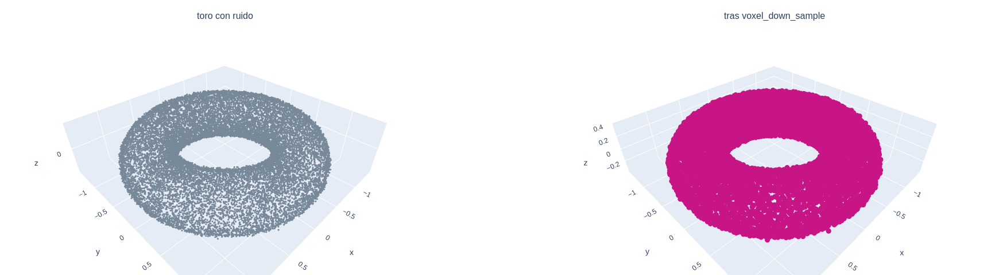

In [8]:
# ✏️ EJERCICIO 1
R, r_tube, n = 1.0, 0.35, 20000
u = rng.uniform(0, 2 * np.pi, n)
v = rng.uniform(0, 2 * np.pi, n)

# TODO 1: construye el array de puntos P_torus de forma (n, 3) con las fórmulas de arriba
def torus_points(u, v):
    rho = R + r_tube * np.cos(v)
    return np.stack([rho * np.cos(u),
                     rho * np.sin(u),
                     r_tube * np.sin(v)], axis=-1)

P_torus = torus_points(u, v)   # (n, 3)

# TODO 2: agrégale ruido gaussiano de desviación estándar 0.01 en las tres coordenadas
P_torus_noisy = P_torus + rng.normal(0, 0.01, P_torus.shape)

# TODO 3: crea un PointCloud de Open3D llamado pcd_torus con esos puntos ruidosos
pcd_torus = o3d.geometry.PointCloud()
pcd_torus.points = o3d.utility.Vector3dVector(P_torus_noisy)

# TODO 4: submuestrea con voxel_down_sample (voxel_size=0.06) y guárdalo en pcd_torus_down
pcd_torus_down = pcd_torus.voxel_down_sample(voxel_size=0.06)

print("puntos originales:", n, "-> submuestreados:", len(pcd_torus_down.points))
side_by_side([show_points(pcd_torus, color="lightslategray", size=1),
              show_points(pcd_torus_down, color="mediumvioletred", size=3)],
             ["toro con ruido", "tras voxel_down_sample"])

In [9]:
# ✅ Verificación del ejercicio 1
Pt = np.asarray(pcd_torus.points)
assert Pt.shape == (n, 3), "pcd_torus debe tener n puntos de dimensión 3"
d_axis = np.hypot(Pt[:, 0], Pt[:, 1]) - R          # distancia al círculo central, en el plano xy
assert np.abs(np.hypot(d_axis, Pt[:, 2]) - r_tube).mean() < 0.02, "los puntos no están sobre el toro"
assert 1000 < len(pcd_torus_down.points) < 6000, "revisa el voxel_size del submuestreo"
print("Ejercicio 1 ✔")

Ejercicio 1 ✔


### ✏️ EJERCICIO 2 — Densidad local con KD-tree &nbsp; ⏱ ~5 min

La **densidad local** es un descriptor barato y muy usado (detectar zonas mal escaneadas, filtrar
outliers, elegir el radio de otros algoritmos). Calcúlala como el número de vecinos dentro de un
radio fijo y píntala sobre la nube.

densidad: min=18  mediana=47  max=91


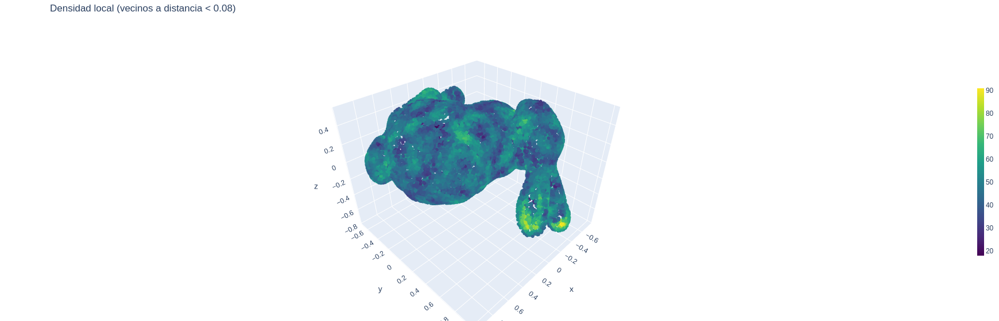

In [10]:
# ✏️ EJERCICIO 2
pcd_ej = bunny.sample_points_uniformly(number_of_points=15000)   # densidad irregular a propósito
P_ej = np.asarray(pcd_ej.points)
radio = 0.08

# TODO 1: construye el KD-tree de pcd_ej
tree_ej = o3d.geometry.KDTreeFlann(pcd_ej)
P_ej = np.asarray(pcd_ej.points)

# TODO 2: para cada punto, cuenta cuántos vecinos hay dentro de 'radio'.
#         Pista: tree_ej.search_radius_vector_3d(punto, radio) devuelve (k, indices, distancias2)
#         Guarda los conteos en un array de enteros llamado densidad, de forma (len(P_ej),)
densidad = np.fromiter(
    (tree_ej.search_radius_vector_3d(p, radio)[0] for p in P_ej),
    dtype=int, count=len(P_ej),
)

print(f"densidad: min={densidad.min()}  mediana={np.median(densidad):.0f}  max={densidad.max()}")
show_points(P_ej, color=densidad, size=2,
            title=f"Densidad local (vecinos a distancia < {radio})")

In [11]:
# ✅ Verificación del ejercicio 2
densidad = np.asarray(densidad)
assert densidad.shape == (len(P_ej),), "densidad debe tener un valor por punto"
assert densidad.min() >= 1, "cada punto es vecino de sí mismo: el mínimo no puede ser 0"
_i = 777
_k, _, _ = o3d.geometry.KDTreeFlann(pcd_ej).search_radius_vector_3d(P_ej[_i], radio)
assert densidad[_i] == _k, "el conteo no coincide con la consulta directa al KD-tree"
print("Ejercicio 2 ✔")

Ejercicio 2 ✔


---
## 2. Mallas poligonales &nbsp; ⏱ ~15 min

Una malla triangular son **dos arrays**:

* `V` de forma `(nV, 3)` — la **geometría**: dónde está cada vértice.
* `F` de forma `(nF, 3)` — la **topología**: qué vértices forman cada triángulo (índices a `V`).

Esta separación es la idea central de toda la sección: puedes mover los vértices sin tocar la
topología (deformación) o cambiar la topología conservando la forma (simplificación, subdivisión).

### 2.1 Una malla mínima, escrita a mano

cara 0 = [0 2 1] -> vértices
 [[0.        0.        0.       ]
 [0.5       0.8660254 0.       ]
 [1.        0.        0.       ]]
¿cerrada (watertight)? True | ¿orientable? True


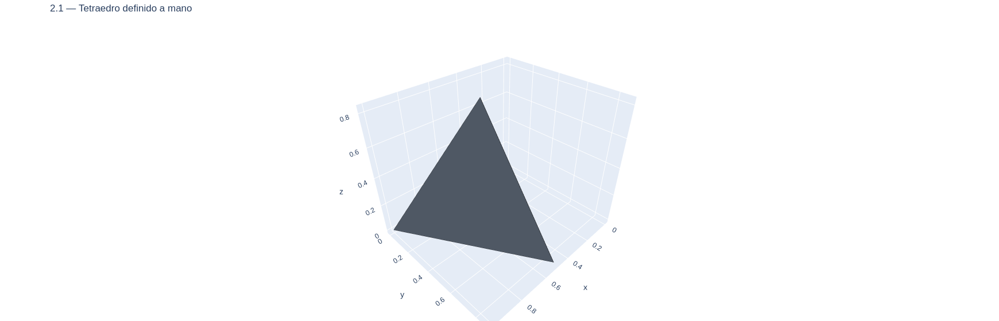

In [12]:
# 🔧 Un tetraedro: 4 vértices, 4 caras
V = np.array([[0, 0, 0], [1, 0, 0], [0.5, np.sqrt(3) / 2, 0], [0.5, np.sqrt(3) / 6, 0.82]])
F = np.array([[0, 2, 1], [0, 1, 3], [1, 2, 3], [2, 0, 3]])   # ¡el orden importa! (regla de la mano derecha)

tet = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(V), o3d.utility.Vector3iVector(F))
tet.compute_vertex_normals()

print("cara 0 =", F[0], "-> vértices\n", V[F[0]])
print("¿cerrada (watertight)?", tet.is_watertight(), "| ¿orientable?", tet.is_orientable())
show_mesh(tet, wireframe=True, flat=True, title="2.1 — Tetraedro definido a mano")

El orden de los índices de cada cara define hacia dónde apunta su normal
($\vec{n} = (v_1 - v_0) \times (v_2 - v_0)$, normalizada). Si inviertes un triángulo, esa cara queda
"al revés" y el render se ve con un agujero negro. Una malla es **orientable** cuando existe una
elección de orden coherente para todas las caras.

### 2.2 Anatomía de una malla real

vértices: 35947   caras: 69451   (≈ 2 caras por vértice, como predice Euler)
bounding box: [-0.738 -0.676 -0.769] -> [0.953 1.    0.541]


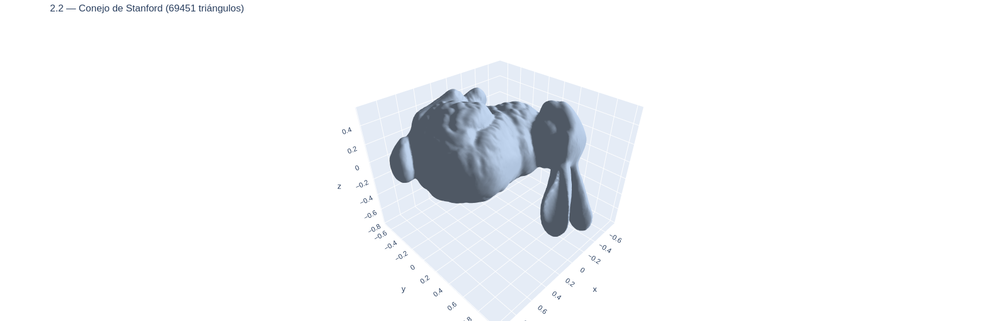

componentes conexas: 1


In [13]:
# 🔧 Propiedades básicas del conejo
mesh = bunny
V = np.asarray(mesh.vertices)
F = np.asarray(mesh.triangles)

print(f"vértices: {len(V)}   caras: {len(F)}   (≈ 2 caras por vértice, como predice Euler)")
print("bounding box:", np.round(V.min(0), 3), "->", np.round(V.max(0), 3))
print("watertight:", mesh.is_watertight(),
      "| edge-manifold:", mesh.is_edge_manifold(),
      "| vertex-manifold:", mesh.is_vertex_manifold())
print("área de superficie:", round(mesh.get_surface_area(), 4))
print("componentes conexas:", len(np.unique(np.asarray(mesh.cluster_connected_triangles()[0]))))

show_mesh(mesh, title=f"2.2 — Conejo de Stanford ({len(F)} triángulos)")

> El conejo **no es watertight**: al escanearlo quedaron agujeros en la base. Muchos algoritmos
> (volumen, booleanas, difusión de calor) asumen una malla cerrada y manifold, así que este chequeo
> es lo primero que se hace al recibir un modelo.

### 2.3 Normales: por cara y por vértice

normales de cara:   (224, 3) (una por triángulo)
normales de vértice: (114, 3) (promedio de las caras incidentes, ponderado por área)


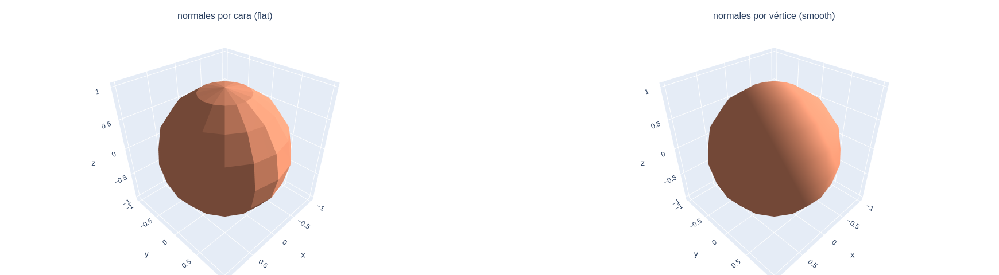

In [14]:
# 🔧 La misma geometría, dos convenciones de sombreado
esfera = o3d.geometry.TriangleMesh.create_sphere(radius=1.0, resolution=8)
plana = copy.deepcopy(esfera); plana.compute_triangle_normals()
suave = copy.deepcopy(esfera); suave.compute_vertex_normals()

print("normales de cara:  ", np.asarray(plana.triangle_normals).shape, "(una por triángulo)")
print("normales de vértice:", np.asarray(suave.vertex_normals).shape,
      "(promedio de las caras incidentes, ponderado por área)")

side_by_side([show_mesh(plana, flat=True, color="lightsalmon"),
              show_mesh(suave, flat=False, color="lightsalmon")],
             ["normales por cara (flat)", "normales por vértice (smooth)"])

### 2.4 Topología: valencia y vecindarios de vértices

caras por vértice -> media: 5.8 | min: 0 | max: 11
vecinos del vértice 100: [71, 1139, 1141, 1142, 3864]


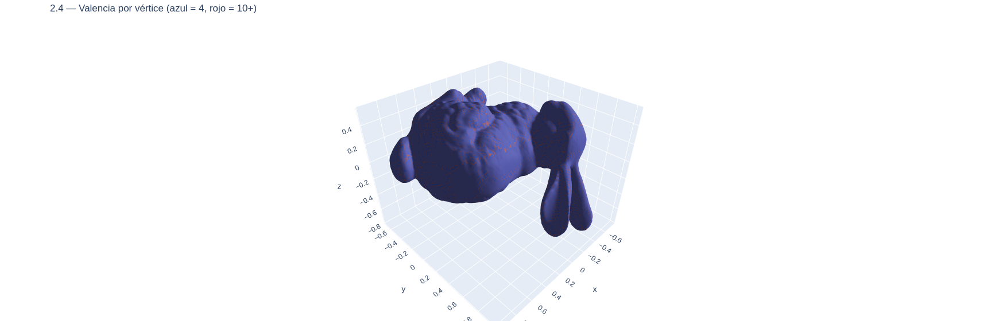

In [15]:
# 🔧 La valencia (grado) de un vértice = cuántas aristas/caras lo tocan.
#    Con np.bincount sobre F.ravel() contamos caras incidentes por vértice.
caras_por_vertice = np.bincount(F.ravel(), minlength=len(V))
print("caras por vértice -> media:", round(caras_por_vertice.mean(), 2),
      "| min:", caras_por_vertice.min(), "| max:", caras_por_vertice.max())

# Open3D también mantiene las adyacencias explícitas:
mesh.compute_adjacency_list()
print("vecinos del vértice 100:", sorted(mesh.adjacency_list[100]))

col = np.zeros((len(V), 3))
c = np.clip((caras_por_vertice - 4) / 6, 0, 1)
col[:, 0], col[:, 1], col[:, 2] = c, 0.35, 1 - c      # rojo = alta valencia
vis = copy.deepcopy(mesh); vis.vertex_colors = o3d.utility.Vector3dVector(col)
show_mesh(vis, title="2.4 — Valencia por vértice (azul = 4, rojo = 10+)")

En una malla "bonita" la valencia se concentra en 6 (la valencia regular de una triangulación en el
plano). Los vértices muy irregulares son justamente los que arruinan el remallado, la subdivisión y
los esquemas numéricos definidos sobre la malla.

### 2.5 Cambiar la topología: subdividir y simplificar

icosaedro  V=    12  F=    20
Loop x1    V=    42  F=    80
Loop x3    V=   642  F=  1280


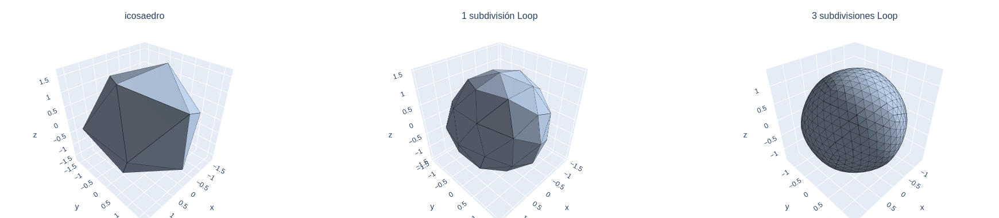

In [16]:
# 🔧 Dos operaciones opuestas sobre la misma geometría
base = o3d.geometry.TriangleMesh.create_icosahedron(radius=1.0)
sub1 = base.subdivide_loop(number_of_iterations=1)
sub3 = base.subdivide_loop(number_of_iterations=3)
for nombre, m in [("icosaedro", base), ("Loop x1", sub1), ("Loop x3", sub3)]:
    print(f"{nombre:10s} V={len(m.vertices):6d}  F={len(m.triangles):6d}")

side_by_side([show_mesh(m, wireframe=True, flat=True) for m in (base, sub1, sub3)],
             ["icosaedro", "1 subdivisión Loop", "3 subdivisiones Loop"], size=(1000, 380))

objetivo  69451 caras -> reales  69451 | área 6.7342
objetivo   5000 caras -> reales   4999 | área 6.6868
objetivo   1000 caras -> reales    999 | área 6.5088
objetivo    200 caras -> reales    199 | área 6.0883


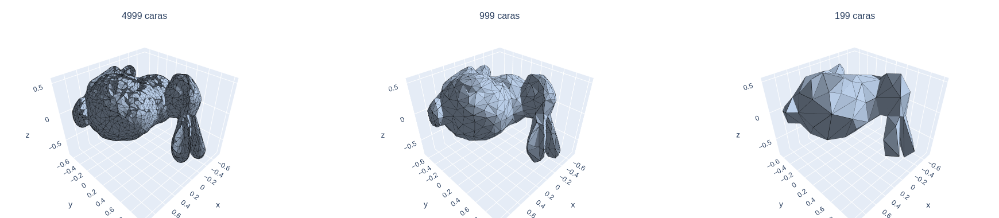

In [17]:
# 🔧 Simplificación por colapso de aristas con métrica cuádrica (QEM)
niveles = [len(F), 5000, 1000, 200]
mallas = [mesh] + [mesh.simplify_quadric_decimation(t) for t in niveles[1:]]
for t, m in zip(niveles, mallas):
    m.compute_vertex_normals()
    print(f"objetivo {t:6d} caras -> reales {len(m.triangles):6d} | "
          f"área {m.get_surface_area():.4f}")

side_by_side([show_mesh(m, wireframe=(len(m.triangles) <= 5000), flat=True) for m in mallas[1:]],
             [f"{len(m.triangles)} caras" for m in mallas[1:]], size=(1000, 380))

El área cae poco a poco mientras los triángulos se concentran donde hay curvatura. Es el mismo
mecanismo que usan los niveles de detalle (LOD) en videojuegos y el preproceso de casi cualquier
método geométrico caro.

### ✏️ EJERCICIO 3 — Área de la malla con numpy &nbsp; ⏱ ~6 min

El área de un triángulo con vértices $a, b, c$ es $\tfrac{1}{2}\lVert (b-a) \times (c-a) \rVert$.
Calcúlala **vectorizadamente** (sin bucles `for`) y compara con `get_surface_area()`.

In [40]:
# ✏️ EJERCICIO 3
V = np.asarray(mesh.vertices)
F = np.asarray(mesh.triangles)

# TODO 1: tres arrays (nF, 3) con las coordenadas de los vértices de cada cara
A, B, C = V[F[:, 0]], V[F[:, 1]], V[F[:, 2]]

# TODO 2: producto cruz por fila (usa np.cross con axis=1) y áreas de cada triángulo -> areas (nF,)
areas = 0.5 * np.linalg.norm(np.cross(B - A, C - A, axis=1), axis=1)

# TODO 3: área total
area_total = areas.sum()

# TODO 4 ★: centroide de la superficie = promedio de los baricentros de las caras
#           PONDERADO por el área de cada cara (no es lo mismo que V.mean(0))
baricentros = V[F].mean(1)                          # (nF, 3): promedio de las 3 esquinas
centroide = (areas[:, None] * baricentros).sum(0) / area_total

print(f"área total (numpy)  = {area_total:.6f}")
print(f"área total (Open3D) = {mesh.get_surface_area():.6f}")
print("centroide ponderado por área:", np.round(centroide, 4),
      "| promedio simple de vértices:", np.round(V.mean(0), 4))
print(f"triángulo más grande / más chico = {areas.max() / areas.min():.0f}x")

área total (numpy)  = 6.734248
área total (Open3D) = 6.734248
centroide ponderado por área: [-0.0004 -0.0117 -0.007 ] | promedio simple de vértices: [-0.  0.  0.]
triángulo más grande / más chico = 545x


In [41]:
# ✅ Verificación del ejercicio 3
assert np.asarray(areas).shape == (len(F),), "areas debe tener un valor por cara"
assert abs(area_total - mesh.get_surface_area()) < 1e-9, "el área total no coincide con Open3D"
assert np.allclose(centroide, (np.asarray(areas)[:, None] * V[F].mean(1)).sum(0) / area_total), \
    "el centroide debe ponderarse por área"
print("Ejercicio 3 ✔")

Ejercicio 3 ✔


### ✏️ EJERCICIO 4 ★ — Aristas y característica de Euler &nbsp; ⏱ ~6 min (opcional)

Para una malla cerrada y orientable de género $g$ (número de "asas") se cumple

$$\chi = |V| - |E| + |F| = 2 - 2g$$

Open3D no te entrega la lista de aristas: hay que **derivarla de las caras**. Cada cara aporta 3
aristas y en una malla cerrada cada arista es compartida por 2 caras.

In [20]:
# ✏️ EJERCICIO 4 ★
def caracteristica_euler(m):
    Vm = np.asarray(m.vertices)
    Fm = np.asarray(m.triangles)

    # TODO 1: array (3*nF, 2) con todas las aristas de todas las caras: (0,1), (1,2), (2,0)
    aristas = None

    # TODO 2: una arista (i,j) y (j,i) son LA MISMA. Normaliza ordenando cada fila
    #         (np.sort con axis=1) y quédate con las únicas (np.unique con axis=0)
    aristas_unicas = None

    # TODO 3: retorna (|V|, |E|, |F|, chi)
    return len(Vm), len(aristas_unicas), len(Fm), None


for nombre, m in [("esfera (g=0)", o3d.geometry.TriangleMesh.create_sphere(resolution=10)),
                  ("toro   (g=1)", o3d.geometry.TriangleMesh.create_torus()),
                  ("conejo (abierto)", mesh)]:
    nv, ne, nf, chi = caracteristica_euler(m)
    print(f"{nombre:18s} V={nv:6d} E={ne:6d} F={nf:6d} chi={chi:4d}  "
          f"watertight={m.is_watertight()}")

TypeError: object of type 'NoneType' has no len()

In [21]:
# ✅ Verificación del ejercicio 4
_s = o3d.geometry.TriangleMesh.create_sphere(resolution=10)
_t = o3d.geometry.TriangleMesh.create_torus()
assert caracteristica_euler(_s)[3] == 2, "la esfera debe dar chi = 2"
assert caracteristica_euler(_t)[3] == 0, "el toro debe dar chi = 0"
assert caracteristica_euler(_s)[1] == 3 * len(_s.triangles) // 2, \
    "en una malla cerrada, |E| = 3|F|/2"
print("Ejercicio 4 ✔  — y fíjate que el conejo NO cumple 2-2g: tiene borde, no es cerrado.")

TypeError: object of type 'NoneType' has no len()

---
## 3. Voxels y grillas de ocupancia &nbsp; ⏱ ~10 min

Un voxel es el equivalente 3D de un píxel: dividimos el espacio en una grilla regular y marcamos
qué celdas están ocupadas. La representación es **regular** (un array `(n, n, n)`), lo que la hace
ideal para convoluciones, operaciones booleanas y redes neuronales 3D... a cambio de un costo de
memoria $O(n^3)$ que crece brutalmente.

Hay que distinguir dos cosas que se confunden todo el tiempo:

* **voxelización de superficie** — se marcan las celdas que *toca* la superficie (una cáscara hueca);
* **voxelización sólida** — se marcan también las celdas del *interior* (requiere una malla cerrada).

### 3.1 De malla a voxels (superficie)

VoxelGrid with 2710 voxels.
voxels ocupados: 2710 | origen: [-0.768 -0.706 -0.799] | tamaño: 0.06


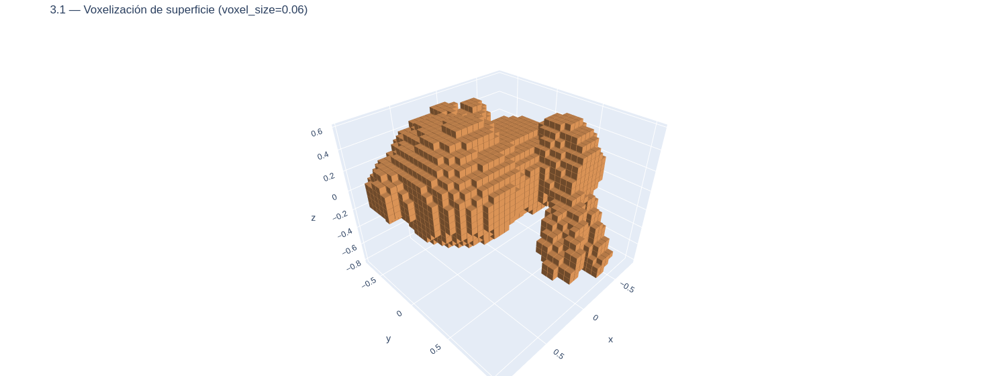

In [42]:
# 🔧 create_from_triangle_mesh marca las celdas atravesadas por algún triángulo
vg = o3d.geometry.VoxelGrid.create_from_triangle_mesh(bunny, voxel_size=0.06)
print(vg)
print("voxels ocupados:", len(vg.get_voxels()), "| origen:", np.round(vg.origin, 3),
      "| tamaño:", vg.voxel_size)
show_voxelgrid(vg, title="3.1 — Voxelización de superficie (voxel_size=0.06)")

voxel_size=0.16 ->    363 ocupados | grilla completa 13^3 =      2197 celdas
voxel_size=0.08 ->   1549 ocupados | grilla completa 25^3 =     15625 celdas
voxel_size=0.04 ->   6191 ocupados | grilla completa 50^3 =    125000 celdas


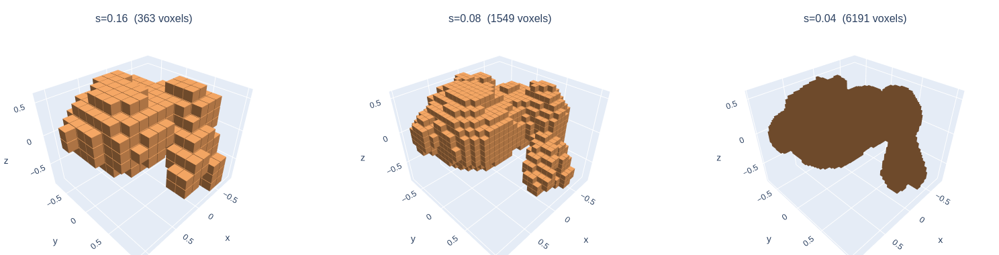

In [43]:
# 🔧 El compromiso resolución / memoria
figs, titulos = [], []
for s in [0.16, 0.08, 0.04]:
    g = o3d.geometry.VoxelGrid.create_from_triangle_mesh(bunny, voxel_size=s)
    n = int(np.ceil(2 / s))
    print(f"voxel_size={s:.2f} -> {len(g.get_voxels()):6d} ocupados | "
          f"grilla completa {n}^3 = {n**3:9d} celdas")
    figs.append(show_voxelgrid(g))
    titulos.append(f"s={s}  ({len(g.get_voxels())} voxels)")
side_by_side(figs, titulos, size=(1000, 380))

### 3.2 De nube de puntos a voxels

voxels desde la nube: 3604


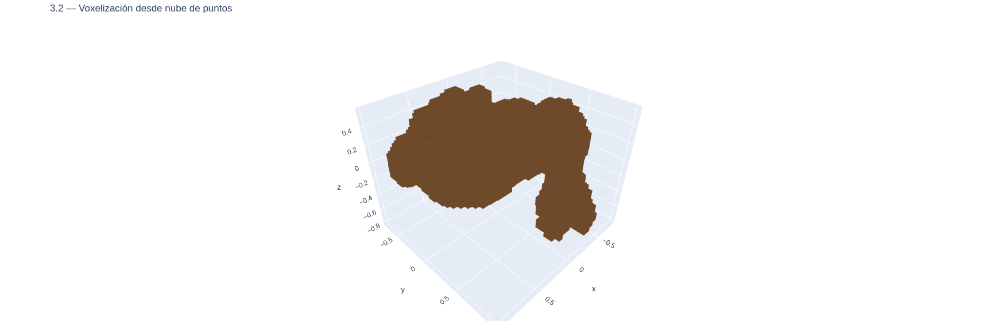

In [24]:
# 🔧 Lo mismo, pero partiendo de una nube (con color): útil para datos de escáner
pcd_col = bunny.sample_points_uniformly(number_of_points=60000)
alt = np.asarray(pcd_col.points)[:, 1]
alt = (alt - alt.min()) / np.ptp(alt)
pcd_col.colors = o3d.utility.Vector3dVector(np.stack([alt, 0.4 * np.ones_like(alt), 1 - alt], 1))

vg_pcd = o3d.geometry.VoxelGrid.create_from_point_cloud(pcd_col, voxel_size=0.05)
print("voxels desde la nube:", len(vg_pcd.get_voxels()))
show_voxelgrid(vg_pcd, title="3.2 — Voxelización desde nube de puntos")

### 3.3 De `VoxelGrid` a un array de numpy

forma de la grilla: (29, 29, 23) | ocupación: 14.0% de las celdas


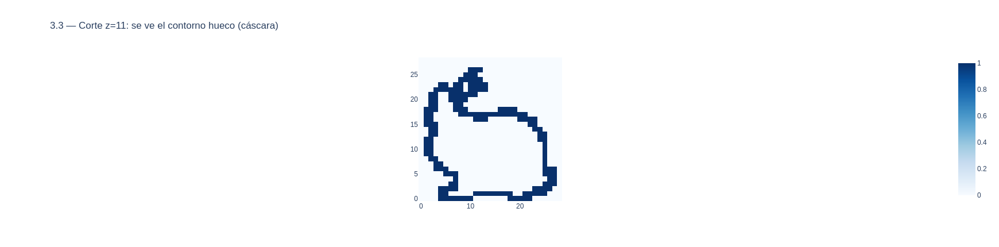

In [25]:
# 🔧 Para hacer cuentas necesitamos la grilla booleana explícita
def a_grilla_numpy(vg):
    idx = np.array([v.grid_index for v in vg.get_voxels()])
    dims = idx.max(0) + 1
    occ = np.zeros(dims, dtype=bool)
    occ[idx[:, 0], idx[:, 1], idx[:, 2]] = True
    return occ

occ = a_grilla_numpy(vg)
print("forma de la grilla:", occ.shape,
      f"| ocupación: {100 * occ.mean():.1f}% de las celdas")

import plotly.express as px
z = occ.shape[2] // 2
px.imshow(occ[:, :, z].T.astype(int), origin="lower", color_continuous_scale="Blues",
          title=f"3.3 — Corte z={z}: se ve el contorno hueco (cáscara)",
          width=430, height=430).show()

El corte deja clarísimo que `create_from_triangle_mesh` produce una **cáscara**: el interior está
vacío. Para preguntas de volumen o para operaciones booleanas necesitamos la versión sólida.

### 3.4 Voxelización sólida con *ray casting*

celdas ocupadas: 46608 de 110592
volumen estimado = 4.1574  vs  4/3·π = 4.1888


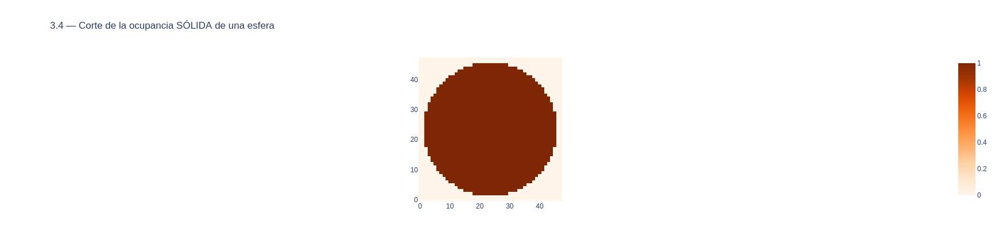

In [26]:
# 🔧 RaycastingScene.compute_occupancy responde "¿este punto está dentro?" (requiere malla cerrada)
def ocupancia_solida(malla, n=48, margen=1.05):
    escena = o3d.t.geometry.RaycastingScene()
    escena.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(malla))
    lo = np.asarray(malla.get_min_bound()); hi = np.asarray(malla.get_max_bound())
    c, mitad = (lo + hi) / 2, margen * (hi - lo) / 2
    ejes = [np.linspace(c[i] - mitad[i], c[i] + mitad[i], n) for i in range(3)]
    G = np.stack(np.meshgrid(*ejes, indexing="ij"), -1).astype(np.float32)
    occ = escena.compute_occupancy(G.reshape(-1, 3)).numpy().reshape(n, n, n) > 0
    paso = np.array([e[1] - e[0] for e in ejes])
    return occ, ejes, paso

esf = o3d.geometry.TriangleMesh.create_sphere(radius=1.0, resolution=20)
occ_s, ejes_s, paso_s = ocupancia_solida(esf, n=48)
print("celdas ocupadas:", occ_s.sum(), "de", occ_s.size)
print(f"volumen estimado = {occ_s.sum() * np.prod(paso_s):.4f}  vs  4/3·π = {4/3*np.pi:.4f}")

px.imshow(occ_s[:, :, 24].T.astype(int), origin="lower", color_continuous_scale="Oranges",
          title="3.4 — Corte de la ocupancia SÓLIDA de una esfera",
          width=430, height=430).show()

### ✏️ EJERCICIO 5 — Volumen por conteo de voxels &nbsp; ⏱ ~6 min

Estima el volumen de un **toro** contando voxels y estudia cómo converge al valor exacto
$V = 2\pi^2 R r^2$ al refinar la grilla.

In [44]:
# ✏️ EJERCICIO 5
R, r_tube = 1.0, 0.4
toro = o3d.geometry.TriangleMesh.create_torus(torus_radius=R, tube_radius=r_tube,
                                              radial_resolution=180, tubular_resolution=120)
V_exacto = 2 * np.pi**2 * R * r_tube**2
print(f"volumen exacto (fórmula) = {V_exacto:.5f} | volumen de la malla = {toro.get_volume():.5f}")

def volumen_por_voxels(malla, n):
    # TODO 1: usa ocupancia_solida(malla, n) para obtener (occ, ejes, paso)
    occ, ejes, paso = ocupancia_solida(malla, n)
    # TODO 2: el volumen es (nº de celdas ocupadas) x (volumen de una celda)
    return occ.sum() * np.prod(paso)

for n in [16, 32, 64, 96]:
    v = volumen_por_voxels(toro, n)
    print(f"n={n:3d} -> V≈{v:.5f}   error relativo = {100*abs(v-V_exacto)/V_exacto:5.2f}%")

# TODO 3: ¿a qué velocidad baja el error al duplicar n? ¿Por qué NO es cuadrática?
#         Escribe tu respuesta en un comentario aquí:
#
# La cota es O(1/n) -- primer orden -- y no O(1/n^2).
#
# Por qué: las celdas totalmente interiores y las totalmente exteriores se clasifican
# siempre bien, así que no aportan error. Las únicas que lo aportan son las que la
# superficie ATRAVIESA: de ellas nos quedamos con todo su volumen o con nada, porque
# compute_occupancy evalúa un solo punto (el centro de la celda). Esas celdas de frontera
# forman una cáscara de 1 celda de espesor sobre una superficie 2D: hay O(n^2) de ellas y
# cada una vale O(1/n^3) de volumen  ->  error total O(n^2 * 1/n^3) = O(1/n).
# Es un error de "todo o nada" por celda, no un error de truncamiento suave, y por eso
# refinar la grilla no gana órdenes como sí lo haría una cuadratura.
#
# Matiz sobre la tabla de arriba (2.45 -> 0.44 -> 0.08 -> 0.07 %): baja MÁS rápido que 1/n
# porque el toro es liso y simétrico, y las celdas que sobran se cancelan casi todas con
# las que faltan; O(1/n) es la cota pesimista, no el caso promedio. Y desde n=64 se estanca
# en ~0.07% porque ahí ya dejamos de medir el error de voxelización: el volumen real de la
# MALLA es 3.15619 (triángulos planos inscritos) contra los 3.15827 de la fórmula, y es a
# ese valor al que converge el conteo. Para bajar de ese piso hay que refinar el toro, no
# la grilla.

volumen exacto (fórmula) = 3.15827 | volumen de la malla = 3.15619
n= 16 -> V≈3.23555   error relativo =  2.45%
n= 32 -> V≈3.17224   error relativo =  0.44%
n= 64 -> V≈3.16086   error relativo =  0.08%
n= 96 -> V≈3.15615   error relativo =  0.07%


In [45]:
# ✅ Verificación del ejercicio 5
_v16, _v96 = volumen_por_voxels(toro, 16), volumen_por_voxels(toro, 96)
assert abs(_v96 - V_exacto) / V_exacto < 0.015, "con n=96 el error debería ser menor al 1.5%"
assert abs(_v96 - V_exacto) < abs(_v16 - V_exacto), "el error debe bajar al refinar la grilla"
print("Ejercicio 5 ✔")
print("Respuesta al TODO 3: el error decae ~O(1/n), no O(1/n²): las celdas mal clasificadas")
print("son las que corta la frontera, y esas son O(n²) de un total de O(n³).")

Ejercicio 5 ✔
Respuesta al TODO 3: el error decae ~O(1/n), no O(1/n²): las celdas mal clasificadas
son las que corta la frontera, y esas son O(n²) de un total de O(n³).


---
## 4. Superficies implícitas (SDF) y *marching cubes* &nbsp; ⏱ ~12 min

En una representación implícita la superficie no se almacena: **se define como el conjunto de nivel
cero de una función**

$$S = \{\, \mathbf{p} \in \mathbb{R}^3 : f(\mathbf{p}) = 0 \,\}$$

Cuando además $f(\mathbf{p})$ vale la **distancia con signo** a la superficie (negativa adentro,
positiva afuera) hablamos de una **SDF** (*signed distance function*). Es una función de Python:
cero memoria, resolución infinita, y las operaciones booleanas se vuelven aritmética elemental.

El precio: para *ver* una SDF hay que convertirla en malla, y ahí entra **marching cubes**.

### 4.1 Primitivas: la SDF como función de numpy

In [29]:
# 🔧 Cada SDF recibe P de forma (..., 3) y devuelve un escalar por punto
def sdf_esfera(P, centro=(0, 0, 0), radio=1.0):
    return np.linalg.norm(P - np.asarray(centro), axis=-1) - radio

def sdf_caja(P, lados=(0.8, 0.8, 0.8)):
    q = np.abs(P) - np.asarray(lados)
    return (np.linalg.norm(np.maximum(q, 0), axis=-1)
            + np.minimum(np.max(q, axis=-1), 0))          # el 2º término corrige el interior

def sdf_toro(P, R=0.9, r=0.3):
    q = np.hypot(P[..., 0], P[..., 2]) - R
    return np.hypot(q, P[..., 1]) - r

p = np.array([[0, 0, 0], [1, 0, 0], [2, 0, 0]], float)
print("esfera(r=1) evaluada en el centro, sobre la superficie y afuera:", sdf_esfera(p))
print("-> negativo = dentro, cero = superficie, positivo = fuera (y es la distancia real)")

esfera(r=1) evaluada en el centro, sobre la superficie y afuera: [-1.  0.  1.]
-> negativo = dentro, cero = superficie, positivo = fuera (y es la distancia real)


### 4.2 De función a malla: *marching cubes*

malla extraída: TriangleMesh with 4632 points and 9260 triangles.
valores de la SDF en la grilla: (48, 48, 48) | rango [-0.94, 1.60]


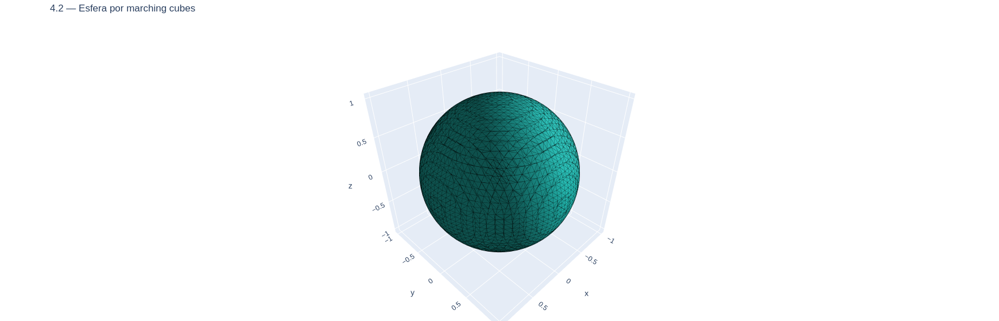

In [30]:
# 🔧 Muestreamos f en una grilla regular y extraemos la isosuperficie f=0
from skimage import measure

def sdf_a_malla(f, limite=1.5, n=64, nivel=0.0):
    ejes = np.linspace(-limite, limite, n)
    P = np.stack(np.meshgrid(ejes, ejes, ejes, indexing="ij"), axis=-1)
    valores = f(P)                                        # (n, n, n)
    paso = ejes[1] - ejes[0]
    v, caras, _, _ = measure.marching_cubes(valores, level=nivel, spacing=(paso,) * 3)
    v = v - limite                                        # de índices de grilla a coordenadas
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(v),
                                  o3d.utility.Vector3iVector(caras))
    m.compute_vertex_normals()
    return m, valores

m_esf, vals = sdf_a_malla(sdf_esfera, n=48)
print("malla extraída:", m_esf)
print("valores de la SDF en la grilla:", vals.shape,
      f"| rango [{vals.min():.2f}, {vals.max():.2f}]")
show_mesh(m_esf, color="lightseagreen", wireframe=True, title="4.2 — Esfera por marching cubes")

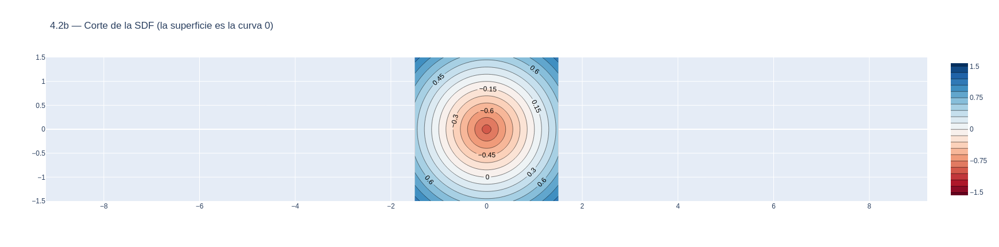

In [31]:
# 🔧 El campo escalar detrás: un corte de la SDF con su curva de nivel cero
import plotly.graph_objects as go
ejes = np.linspace(-1.5, 1.5, 48)
corte = vals[:, :, 24].T
go.Figure(go.Contour(z=corte, x=ejes, y=ejes, colorscale="RdBu", zmid=0,
                     contours=dict(start=-1.5, end=1.5, size=0.15,
                                   showlabels=True))
          ).update_layout(title="4.2b — Corte de la SDF (la superficie es la curva 0)",
                          width=470, height=430, yaxis_scaleanchor="x").show()

### 4.3 Operaciones booleanas: aritmética sobre funciones

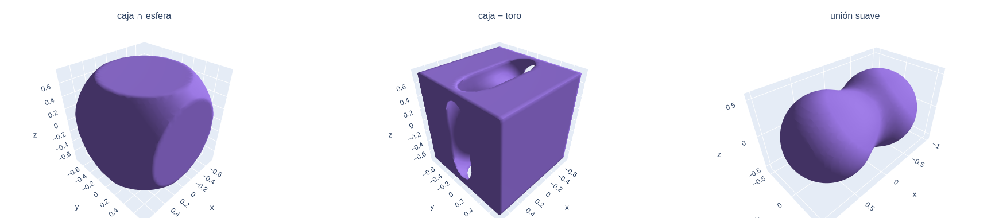

In [32]:
# 🔧 Lo que en mallas es un algoritmo difícil, en SDF es min/max
def union(a, b):        return np.minimum(a, b)
def interseccion(a, b): return np.maximum(a, b)
def diferencia(a, b):   return np.maximum(a, -b)          # a menos b

def union_suave(a, b, k=0.25):                            # blending: imposible de hacer así en mallas
    h = np.clip(0.5 + 0.5 * (b - a) / k, 0, 1)
    return b * (1 - h) + a * h - k * h * (1 - h)

f_caja = lambda P: sdf_caja(P, (0.75, 0.75, 0.75))
f_esf  = lambda P: sdf_esfera(P, radio=0.98)
f_tor  = lambda P: sdf_toro(P, R=0.75, r=0.22)

ejemplos = {
    "caja ∩ esfera":     lambda P: interseccion(f_caja(P), f_esf(P)),
    "caja − toro":       lambda P: diferencia(f_caja(P), f_tor(P)),
    "unión suave":       lambda P: union_suave(sdf_esfera(P, (-0.45, 0, 0), 0.55),
                                               sdf_esfera(P, (0.45, 0, 0), 0.55), k=0.3),
}
figs = [show_mesh(sdf_a_malla(f, n=72)[0], color="mediumpurple", flat=False)
        for f in ejemplos.values()]
side_by_side(figs, list(ejemplos.keys()), size=(1000, 380))

> **Por qué importa.** La intersección booleana de dos mallas es un algoritmo delicado (intersecciones
> triángulo-triángulo, robustez numérica, retriangulación). Con SDF es `np.maximum`. Ese es el trueque
> central del enfoque implícito, y la razón de que el modelado por SDF sea tan popular en gráficos
> (*ray marching*) y en aprendizaje profundo 3D (redes que aprenden $f$).

n= 16 ->     64 triángulos
n= 32 ->    544 triángulos


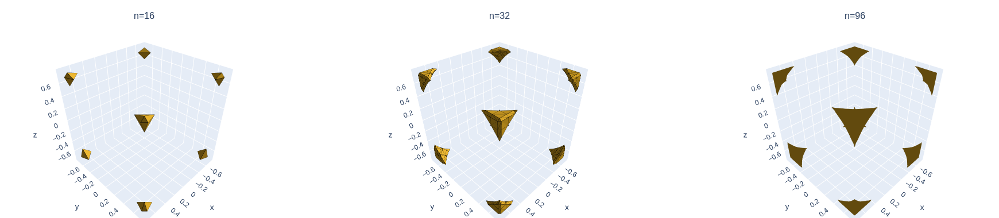

In [33]:
# 🔧 La resolución de la grilla se paga en calidad, no en definición del objeto
figs = []
for n in [16, 32, 96]:
    m, _ = sdf_a_malla(lambda P: diferencia(f_caja(P), f_esf(P) - 0.15), n=n)
    figs.append(show_mesh(m, color="goldenrod", flat=True,
                          wireframe=(n <= 32)))
    print(f"n={n:3d} -> {len(m.triangles):6d} triángulos")
side_by_side(figs, ["n=16", "n=32", "n=96"], size=(1000, 380))

### ✏️ EJERCICIO 6 — Modelar con SDF &nbsp; ⏱ ~7 min

Construye la clásica "esfera-caja perforada": la **intersección** de una esfera y una caja, a la que
se le **restan tres cilindros** ortogonales (uno por eje).

La SDF de un cilindro infinito de radio $\rho$ a lo largo del eje $z$ es
$\;\sqrt{x^2 + y^2} - \rho$.

triángulos: 40480 | cerrada: True


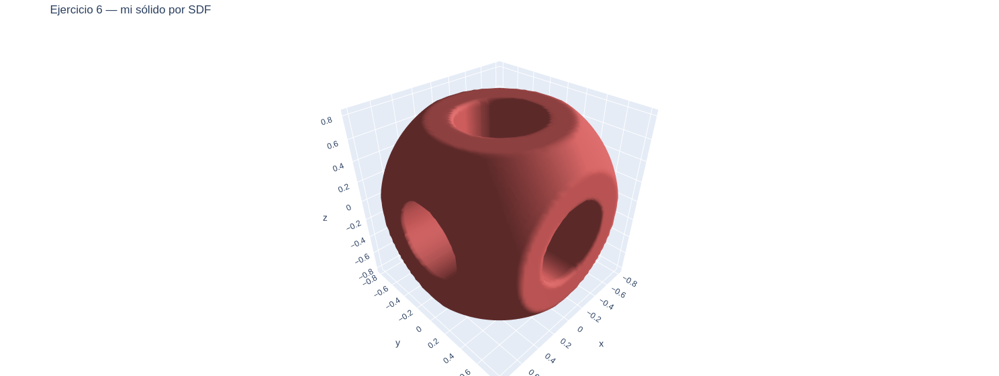

In [46]:
# ✏️ EJERCICIO 6
def sdf_cilindro_z(P, radio=0.35):
    # TODO 1: cilindro infinito alineado con el eje z
    return np.hypot(P[..., 0], P[..., 1]) - radio      # distancia al eje z: usa x, y

def sdf_cilindro_x(P, radio=0.35):
    # TODO 2: el mismo, pero alineado con el eje x
    return np.hypot(P[..., 1], P[..., 2]) - radio      # distancia al eje x: usa y, z

def sdf_cilindro_y(P, radio=0.35):
    # TODO 3: y con el eje y
    return np.hypot(P[..., 0], P[..., 2]) - radio      # distancia al eje y: usa x, z

def mi_solido(P):
    # TODO 4: intersección de una esfera de radio 1.0 con una caja de lados (0.8, 0.8, 0.8),
    #         y a ese sólido réstale los tres cilindros de radio 0.35
    cuerpo = interseccion(sdf_esfera(P, radio=1.0), sdf_caja(P, (0.8, 0.8, 0.8)))
    huecos = union(union(sdf_cilindro_x(P), sdf_cilindro_y(P)), sdf_cilindro_z(P))
    return diferencia(cuerpo, huecos)                  # max(cuerpo, -huecos)

malla_ej, _ = sdf_a_malla(mi_solido, limite=1.5, n=96)
print("triángulos:", len(malla_ej.triangles), "| cerrada:", es_cerrada(malla_ej))
show_mesh(malla_ej, color="indianred", flat=False, title="Ejercicio 6 — mi sólido por SDF")

In [47]:
# ✅ Verificación del ejercicio 6
_q = np.array([[0., 0., 0.],        # centro: dentro del hueco de los cilindros -> FUERA del sólido
               [0.7, 0.7, 0.7],     # esquina de la caja, fuera de la esfera     -> FUERA
               [0.78, 0., 0.],      # cara de la caja, lejos de los ejes... casi la superficie
               [0.6, 0.6, 0.0]])    # dentro de caja y esfera, fuera de los cilindros -> DENTRO
_v = mi_solido(_q)
assert _v[0] > 0, "el origen debe quedar FUERA (lo vacían los cilindros)"
assert _v[1] > 0, "la esquina (0.7,0.7,0.7) está fuera de la esfera de radio 1"
assert _v[3] < 0, "el punto (0.6,0.6,0) debe quedar DENTRO del sólido"
assert es_cerrada(malla_ej), "marching cubes sobre una SDF acotada debe dar una malla sin borde"
print("Ejercicio 6 ✔")

Ejercicio 6 ✔


---
## 5. Superficies paramétricas &nbsp; ⏱ ~6 min

La cuarta representación va en la dirección contraria a la implícita: en vez de *testear* si un punto
pertenece a la superficie, la **generamos** con un mapa

$$\mathbf{x}(u, v) : [0,1]^2 \rightarrow \mathbb{R}^3$$

Es trivial obtener puntos sobre la superficie (evalúas), pero es difícil saber si un punto está
dentro (tendrías que invertir el mapa). Es la base de las NURBS del diseño asistido por computador.

Lo bueno: la **topología de la malla sale gratis** de la grilla $(u, v)$.

### 5.1 De grilla paramétrica a malla

TriangleMesh with 2880 points and 5664 triangles. | cerrada: False (tiene borde arriba y abajo)


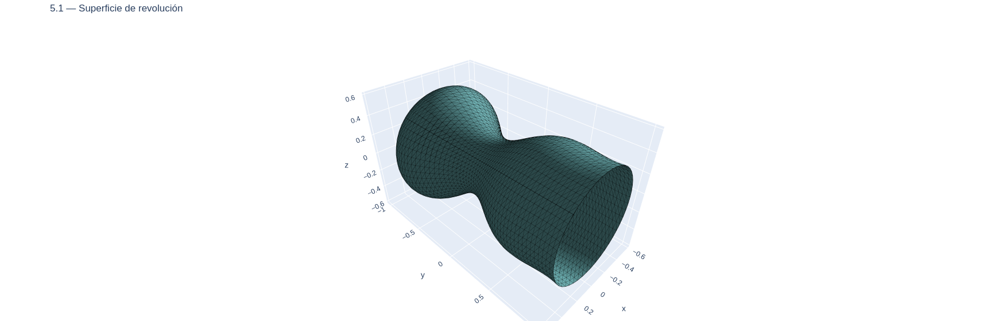

In [36]:
# 🔧 Cada celda de la grilla (u,v) se parte en dos triángulos.
#    wrap_u / wrap_v cosen el borde consigo mismo (superficies cerradas: cilindro, toro...).
def grilla_a_malla(X, wrap_u=False, wrap_v=False):
    nu, nv, _ = X.shape
    idx = np.arange(nu * nv).reshape(nu, nv)
    us = np.arange(nu if wrap_u else nu - 1)
    vs = np.arange(nv if wrap_v else nv - 1)
    U, V = np.meshgrid(us, vs, indexing="ij")
    a = idx[U % nu, V % nv]
    b = idx[(U + 1) % nu, V % nv]
    c = idx[(U + 1) % nu, (V + 1) % nv]
    d = idx[U % nu, (V + 1) % nv]
    F = np.concatenate([np.stack([a, b, c], -1).reshape(-1, 3),
                        np.stack([a, c, d], -1).reshape(-1, 3)])
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(X.reshape(-1, 3)),
                                  o3d.utility.Vector3iVector(F))
    m.compute_vertex_normals()
    return m

# Ejemplo: una superficie de revolución (un jarrón) girando un perfil r(t) alrededor del eje y
t = np.linspace(0, 1, 60)
perfil = 0.35 + 0.25 * np.sin(3.1 * np.pi * t) * (1 - t) + 0.15 * t
theta = np.linspace(0, 2 * np.pi, 48, endpoint=False)      # endpoint=False + wrap_v: sin costura
T, TH = np.meshgrid(t, theta, indexing="ij")
Rr = np.interp(T, t, perfil)
X = np.stack([Rr * np.cos(TH), 2 * T - 1, Rr * np.sin(TH)], axis=-1)

jarron = grilla_a_malla(X, wrap_v=True)
print(jarron, "| cerrada:", es_cerrada(jarron), "(tiene borde arriba y abajo)")
show_mesh(jarron, color="cadetblue", wireframe=True, title="5.1 — Superficie de revolución")

### ✏️ EJERCICIO 7 ★ — El toro, por tercera vez &nbsp; ⏱ ~6 min (opcional)

Ya construiste un toro como **nube** (ejercicio 1) y lo viste como **implícita** (sección 4).
Ahora constrúyelo como **superficie paramétrica**, con su topología correcta:

$$\mathbf{x}(u,v) = \big((R + r\cos v)\cos u,\;\; r\sin v,\;\; (R + r\cos v)\sin u\big)$$

Si la malla queda bien cosida en las dos direcciones, debe ser cerrada y cumplir $\chi = 0$.

In [37]:
# ✏️ EJERCICIO 7 ★
R, r_tube, nu, nv = 1.0, 0.35, 64, 32

# TODO 1: mallas de parámetros U, V de forma (nu, nv). ¡Usa endpoint=False en ambos linspace!
#         (si repites el último punto, la costura queda duplicada y la malla no cierra)
U, V = None, None

# TODO 2: arma X de forma (nu, nv, 3) con la parametrización de arriba
X = None

# TODO 3: llama a grilla_a_malla con el "wrap" correcto en AMBAS direcciones
toro_param = None

print(toro_param, "| cerrada:", es_cerrada(toro_param))
show_mesh(toro_param, color="darkorange", wireframe=True, title="Ejercicio 7 — toro paramétrico")

AttributeError: 'NoneType' object has no attribute 'is_edge_manifold'

In [38]:
# ✅ Verificación del ejercicio 7
assert len(toro_param.vertices) == nu * nv, "no debe haber vértices duplicados en la costura"
assert es_cerrada(toro_param), "el toro debe quedar cerrado: revisa endpoint=False y los wrap"
assert len(toro_param.vertices) - 3 * len(toro_param.triangles) // 2 + len(toro_param.triangles) == 0, \
    "la característica de Euler de un toro debe ser 0"
assert abs(toro_param.get_surface_area() - 4 * np.pi**2 * R * r_tube) / \
       (4 * np.pi**2 * R * r_tube) < 0.01, "el área debería aproximar 4·π²·R·r"
print("Ejercicio 7 ✔")

AttributeError: 'NoneType' object has no attribute 'vertices'

---
## 6. Cierre: el mapa de conversiones

Ninguna representación gana siempre; lo que se hace en la práctica es **cambiar de representación
según la operación**. Este es el resumen de lo que usamos hoy:

| De ↓ / A → | Nube | Malla | Voxels | Implícita |
|---|---|---|---|---|
| **Nube** | `voxel_down_sample` | reconstrucción (Poisson, ball pivoting) | `VoxelGrid.create_from_point_cloud` | ajuste local / redes neuronales |
| **Malla** | `sample_points_uniformly` / `poisson_disk` | subdivisión, simplificación | `create_from_triangle_mesh`, ray casting | `RaycastingScene.compute_signed_distance` |
| **Voxels** | centros de celda | *marching cubes* | remuestreo | interpolación trilineal del campo |
| **Implícita** | muestreo + proyección | *marching cubes* | evaluar en la grilla | composición (min / max) |

**La regla que conviene recordar:** *booleanas y offsets* → implícita; *vecindarios y datos crudos* →
nube; *render, geodésicas y simulación* → malla; *convoluciones y aprendizaje* → voxels.

malla: 27116 caras | nube: 4000 puntos | voxels: 1991


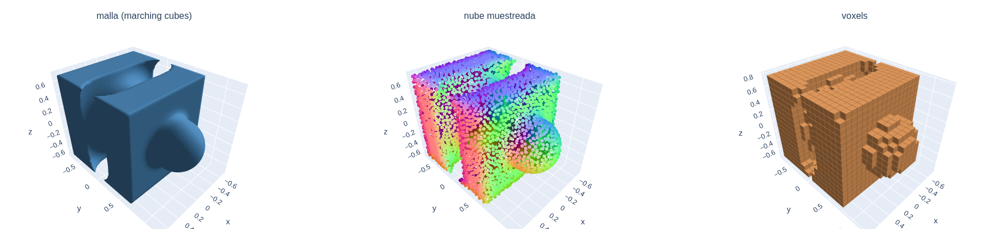

In [39]:
# 🔧 Un objeto, cuatro representaciones: el recorrido completo en una celda
f = lambda P: union_suave(diferencia(sdf_caja(P, (0.7, 0.7, 0.7)), sdf_toro(P, 0.75, 0.25)),
                          sdf_esfera(P, (0, 0.85, 0), 0.35), k=0.15)

malla_fin, _ = sdf_a_malla(f, limite=1.6, n=96)          # implícita -> malla
nube_fin = malla_fin.sample_points_poisson_disk(4000)   # malla -> nube
nube_fin.estimate_normals(o3d.geometry.KDTreeSearchParamKNN(30))
vg_fin = o3d.geometry.VoxelGrid.create_from_triangle_mesh(malla_fin, 0.09)  # malla -> voxels

print(f"malla: {len(malla_fin.triangles)} caras | nube: {len(nube_fin.points)} puntos | "
      f"voxels: {len(vg_fin.get_voxels())}")
side_by_side([show_mesh(malla_fin, color="steelblue"),
              show_points(nube_fin, color=(0.5 * np.asarray(nube_fin.normals) + 0.5), size=2),
              show_voxelgrid(vg_fin)],
             ["malla (marching cubes)", "nube muestreada", "voxels"], size=(1000, 400))

---
## Lo que te llevas

* Una nube es un array `(N, 3)`: **toda** la información local (normales, densidad, curvatura) se
  calcula con un KD-tree, y el resultado depende de cómo elijas el vecindario.
* Una malla separa **geometría** (`V`) de **topología** (`F`); antes de aplicarle cualquier algoritmo
  hay que preguntarle si es *watertight* y *manifold*.
* Los voxels regularizan el problema a costa de $O(n^3)$, y no es lo mismo voxelizar la superficie
  que el sólido.
* Una SDF convierte el modelado booleano en aritmética; *marching cubes* es el puente de vuelta a
  las mallas.
* Las paramétricas te regalan la topología, pero no responden "¿está adentro?".

**Para seguir:** reconstrucción de superficies (Poisson, ball pivoting), operador de Laplace-Beltrami
sobre mallas, parametrización y remallado, y campos implícitos aprendidos (DeepSDF, occupancy
networks).